# AI for Trustworthy Decision Making — Stage 1
# Notebook C (extra): better features
## Federated Human Activity Recognition on WISDM Actitracker

**Team:** Yannick Koning, Mihai-Dragos Toma

**Question:** do better hand-made features help, centralised and federated?

In notebooks A and B, the repository's `split_data.py` summarises every 10-second window with only **mean, std, min and max** per column (12 or 32 numbers). These numbers say how strong the movement is, but not **how it changes over time** (rhythm, speed, repetition). Here we compute **71 features** per window ourselves, in the spirit of the original WISDM work (Kwapisz et al., 2011), and train the same models on them.

**Fair comparison:** we take the clients, windows and test users of notebook A (`user5_basic`) exactly as they are. Only the features change. Then we run the same repository scripts (`centralised.py`, `run_seeds.py`).

This notebook builds on notebooks A and B: it uses their client splits and results.

## Setup

In [9]:
import os, sys, json, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/AITDM_WISDM_stage1")   # shared by notebooks A and B
    REPO = Path("/content/AITDM_FLOWER_PROJECT_TUTORIAL")
    WORK = Path("/content/work")                                  # big temporary files (not in Drive)
else:  # local Jupyter
    PROJECT = Path(os.environ.get("AITDM_PROJECT", "AITDM_WISDM_stage1")).resolve()
    REPO = Path(os.environ.get("AITDM_REPO", PROJECT.parent / "AITDM_FLOWER_PROJECT_TUTORIAL")).resolve()
    WORK = PROJECT.parent / "work"
WORK.mkdir(parents=True, exist_ok=True)

# 1) the course repository
if not REPO.exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/Chiru-CatalinMihail/AITDM_FLOWER_PROJECT_TUTORIAL.git", str(REPO)], check=True)

# 2) its data/ and outputs/ folders live in Drive
for name in ["data", "outputs"]:
    (PROJECT / name).mkdir(parents=True, exist_ok=True)
    link = REPO / name
    if link.is_symlink() and os.path.realpath(link) != str((PROJECT / name).resolve()):
        link.unlink()                       # left over from another Drive folder: re-point it
    if not link.exists():
        link.symlink_to(PROJECT / name, target_is_directory=True)

# 3) install the packages (once)
try:
    import flwr, aitdm_fl
except ImportError:
    reqs = [l for l in (REPO / "requirements.txt").read_text().splitlines()
            if not l.startswith(("torch==", "torchvision=="))]
    (REPO / "requirements-colab.txt").write_text("\n".join(reqs))
    !pip install -q -r {REPO}/requirements-colab.txt
    !pip install -q -e {REPO}/fl_app

os.environ.setdefault("VIRTUAL_ENV", sys.prefix)  # the repo scripts expect an active environment
os.environ["CLIENT_CPUS"] = "1"                     # Flower: 2 clients train in parallel on Colab's 2 CPUs
os.chdir(REPO)
sys.path.insert(0, str(REPO / "experiments"))

PART = PROJECT / "data" / "partitions"
EXP = PROJECT / "outputs" / "experiments"
FIG = PROJECT / "figures"; FIG.mkdir(exist_ok=True)

# the 4 data variants (made in notebook A); every one uses the same 56 test users
VARIANTS = {
    "basic":        "12 features: mean/std/min/max of x, y, z",
    "rich":         "32 features: + magnitude and changes between readings",
    "overlap":      "12 features, 2x training windows (50 % overlap)",
    "rich_overlap": "32 features, 2x training windows",
}
import flwr, torch
print("flwr", flwr.__version__, "| torch", torch.__version__, "| results in", PROJECT)

SOURCE = PART / "user5_basic"            # clients, windows and test users from notebook A
NEW = PART / "user5_handcrafted"         # same data, new features
assert (SOURCE / "meta.json").exists(), "Run notebook A first"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
flwr 1.41.0 | torch 2.14.1+cpu | results in /content/drive/MyDrive/AITDM_WISDM_stage1


## 1. The new features

For every window we take 4 signals: x, y, z and the magnitude `Mag` (which does not depend on how the phone is held). For each signal we compute 17 numbers:

| Group | Features | What they capture |
|---|---|---|
| Level and spread | mean, std, min, max, 10/25/50/75/90th percentile | how strong the movement is (as in A, plus percentiles) |
| Change | mean absolute change between readings | how jerky the movement is |
| Rhythm | how often the signal crosses its mean | how fast it repeats (steps!) |
| Frequency | dominant frequency, share of energy in 0–1, 1–3, 3–5, 5–10 Hz, total energy | walking ≈ 2 steps/s, jogging faster, sitting ≈ no rhythm |

Plus the 3 correlations between the axes (x–y, x–z, y–z). In total 4 × 17 + 3 = **71 features**.

Example: Walking and Stairs have a similar *level* of movement (similar mean/std), but a different *rhythm*. The frequency features can see that, mean/std cannot.

In [10]:
import numpy as np, pandas as pd

def make_features(readings):
    # readings: one row per reading, 200 rows per window -> one row of 71 features per window
    readings = readings.sort_values("Window", kind="stable")          # keep the time order inside each window
    w = readings[["X", "Y", "Z", "Mag"]].to_numpy().reshape(-1, 200, 4)   # windows x time x signals
    labels = readings.groupby("Window", sort=True).Activity.first().to_numpy()

    freqs = np.fft.rfftfreq(200, d=1 / 20)                             # 20 readings per second
    centred = w - w.mean(axis=1, keepdims=True)
    power = np.abs(np.fft.rfft(centred, axis=1))[:, 1:] ** 2           # energy per frequency (without 0 Hz)
    share = power / (power.sum(axis=1, keepdims=True) + 1e-12)

    f = {}
    for j, s in enumerate(["x", "y", "z", "mag"]):
        sig = w[:, :, j]
        f[f"mean_{s}"], f[f"std_{s}"] = sig.mean(1), sig.std(1)
        f[f"min_{s}"], f[f"max_{s}"] = sig.min(1), sig.max(1)
        for p in [10, 25, 50, 75, 90]:
            f[f"p{p}_{s}"] = np.percentile(sig, p, axis=1)
        f[f"change_{s}"] = np.abs(np.diff(sig, axis=1)).mean(1)
        f[f"crossings_{s}"] = (np.diff(np.sign(centred[:, :, j]), axis=1) != 0).mean(1)
        f[f"domfreq_{s}"] = freqs[1:][power[:, :, j].argmax(1)]
        for lo, hi in [(0, 1), (1, 3), (3, 5), (5, 11)]:
            f[f"band{lo}-{hi}Hz_{s}"] = share[:, (freqs[1:] >= lo) & (freqs[1:] < hi), j].sum(1)
        f[f"energy_{s}"] = np.log1p(power[:, :, j].mean(1))
    for a, b in [(0, 1), (0, 2), (1, 2)]:
        f[f"corr_{'xyz'[a]}{'xyz'[b]}"] = np.array([np.corrcoef(x[:, a], x[:, b])[0, 1] for x in w])
    return pd.DataFrame(f).fillna(0), labels

# quick check on the test set
test_features, _ = make_features(pd.read_csv(SOURCE / "test.csv"))
print(test_features.shape)
test_features.head(3).round(2)

(2680, 71)


,mean_x,std_x,min_x,max_x,p10_x,p25_x,p50_x,p75_x,p90_x,change_x,...,crossings_mag,domfreq_mag,band0-1Hz_mag,band1-3Hz_mag,band3-5Hz_mag,band5-11Hz_mag,energy_mag,corr_xy,corr_xz,corr_yz
0,-0.55,4.04,-10.34,13.53,-5.24,-2.87,-1.18,1.78,4.61,4.35,...,0.39,2.2,0.01,0.38,0.19,0.42,8.46,-0.26,-0.16,0.41
1,-0.20,3.95,-9.00,13.18,-4.96,-2.69,-0.42,2.38,4.46,4.05,...,0.38,2.2,0.01,0.36,0.20,0.43,8.43,-0.18,-0.16,0.46
2,0.30,4.14,-10.34,14.18,-4.95,-2.08,0.32,2.57,4.79,4.40,...,0.33,2.3,0.01,0.48,0.13,0.39,8.52,-0.18,-0.11,0.44


## 2. Build the new client files

For every client we read its training and validation readings (saved by `split_data.py` in notebook A), compute the features, and save them in the same format the repository uses (`client_<i>.npz`, `test.npz`, `meta.json`). Labels keep the same numbering.

**Scaling.** The features have very different scales (frequencies in Hz, correlations between −1 and 1, energies in the thousands), so we z-score them. To stay federated, each client would only share the **sum** and **sum of squares** of its training features, never the windows; from these the server gets the mean and std. The validation and test data are not used for this.

In [11]:
meta = json.loads((SOURCE / "meta.json").read_text())
classes = meta["class_names"]
to_label = lambda acts: np.array([classes.index(a) for a in acts])

if not (NEW / "meta.json").exists():
    NEW.mkdir(parents=True, exist_ok=True)
    clients = []
    for c in meta["clients"]:
        i = c["client"]
        x_tr, a_tr = make_features(pd.read_csv(SOURCE / f"client_{i}_train.csv"))
        x_va, a_va = make_features(pd.read_csv(SOURCE / f"client_{i}_val.csv"))
        clients.append((x_tr.to_numpy(), to_label(a_tr), x_va.to_numpy(), to_label(a_va)))
        print(f"client {i}: {len(x_tr)} train, {len(x_va)} val windows")
    x_te, a_te = make_features(pd.read_csv(SOURCE / "test.csv"))
    names = list(x_te.columns)

    # federated scaling: each client shares only n, sum and sum of squares of its training features
    n = sum(len(x) for x, _, _, _ in clients)
    total = sum(x.sum(0) for x, _, _, _ in clients)
    total_sq = sum((x ** 2).sum(0) for x, _, _, _ in clients)
    mean = total / n
    std = np.sqrt(np.maximum(total_sq / n - mean ** 2, 0)) + 1e-8
    scale = lambda x: ((x - mean) / std).astype(np.float32)

    for i, (xt, yt, xv, yv) in enumerate(clients):
        np.savez_compressed(NEW / f"client_{i}.npz", x_train=scale(xt), y_train=yt, x_val=scale(xv), y_val=yv)
    np.savez_compressed(NEW / "test.npz", x_test=scale(x_te.to_numpy()), y_test=to_label(a_te))
    meta.update(feature_names=names, sample_shape=[len(names)], note="hand-crafted features, notebook C")
    (NEW / "meta.json").write_text(json.dumps(meta, indent=2))
print("features per window:", len(json.loads((NEW / "meta.json").read_text())["feature_names"]))

features per window: 71


## 3. Train: centralised MLP, Random Forest and FedAvg

The same repository scripts and settings as in notebooks A and B (MLP `features → 256 → 128 → 6`, 30 epochs centralised / 10 rounds × 3 local epochs federated, seeds 1, 2, 3).

In [12]:
if not (EXP / "central-handcrafted" / "summary.json").exists():
    !python experiments/centralised.py --partitions {NEW} --epochs 30 --seeds 1 2 3 --name central-handcrafted > {WORK}/central_handcrafted.log 2>&1
!tail -3 {WORK}/central_handcrafted.log

  val   acc. 0.938 ± 0.003, bal. acc. 0.927 ± 0.002, macro-F1 0.924 ± 0.007
  test  acc. 0.828 ± 0.015, bal. acc. 0.729 ± 0.039, macro-F1 0.700 ± 0.028
  val per client: 0: 0.931 ± 0.011, 1: 0.933 ± 0.006, 2: 0.953 ± 0.003, 3: 0.923 ± 0.002, 4: 0.950 ± 0.005


In [5]:
!python experiments/run_seeds.py --partitions {NEW} --seeds 1 2 3 --name fedavg-handcrafted --config "num-server-rounds=10 local-epochs=3 strategy='fedavg'" < /dev/null
!bash scripts/stop_flower.sh

>>> fedavg-handcrafted seed 1
>>> fedavg-handcrafted seed 2
>>> fedavg-handcrafted seed 3

fedavg-handcrafted (3 seeds, mean +- std)
  val   acc. 0.866 ± 0.017, bal. acc. 0.753 ± 0.029, macro-F1 0.789 ± 0.027
  test  acc. 0.829 ± 0.004, bal. acc. 0.603 ± 0.015, macro-F1 0.589 ± 0.026
  val per client: 0: 0.802 ± 0.061, 1: 0.857 ± 0.011, 2: 0.871 ± 0.010, 3: 0.875 ± 0.003, 4: 0.924 ± 0.009
Stopped flower-superlink
Stopped flower-superexec


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score

data = [np.load(NEW / f"client_{i}.npz") for i in range(5)]
X = np.concatenate([d["x_train"] for d in data]); y = np.concatenate([d["y_train"] for d in data])
test = np.load(NEW / "test.npz")
rf_rows = []
for seed in [1, 2, 3]:
    pred = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=seed).fit(X, y).predict(test["x_test"])
    rf_rows.append([accuracy_score(test["y_test"], pred), balanced_accuracy_score(test["y_test"], pred)])
rf_rows = np.array(rf_rows)
print(f"Random Forest, test acc. {rf_rows[:, 0].mean():.3f} ± {rf_rows[:, 0].std(ddof=1):.3f}, "
      f"bal. acc. {rf_rows[:, 1].mean():.3f} ± {rf_rows[:, 1].std(ddof=1):.3f}")

Random Forest, test acc. 0.839 ± 0.000, bal. acc. 0.720 ± 0.006


## 4. Comparison with notebooks A and B

Same clients, windows and test users (56 new people); only the features differ.

In [7]:
from summarize import summarize_experiment
import matplotlib.pyplot as plt

def ms(stat):
    return f"{stat['mean']:.3f} ± {stat['std']:.3f}"

feature_sets = {"basic (12, repo)": "basic", "rich (32, repo)": "rich", "hand-crafted (71, ours)": "handcrafted"}
rows, S = [], {}
for label, v in feature_sets.items():
    for method in ["central", "fedavg"]:
        s = S[(v, method)] = summarize_experiment(EXP / f"{method}-{v}", quiet=True)
        rows.append({"Features": label, "Method": "centralised MLP" if method == "central" else "FedAvg (per-user)",
                     "Test acc.": ms(s["test"]["accuracy"]), "Test bal. acc.": ms(s["test"]["balanced_accuracy"]),
                     "Test macro-F1": ms(s["test"]["f1_macro"]),
                     "Worst client val acc.": ms(s["val_worst_client_accuracy"])})
table = pd.DataFrame(rows)
table.to_csv(PROJECT / "results" / "features_comparison.csv", index=False)
table

,Features,Method,Test acc.,Test bal. acc.,Test macro-F1,Worst client val acc.
0,"basic (12, repo)",centralised MLP,0.796 ± 0.001,0.641 ± 0.004,0.621 ± 0.002,0.865 ± 0.017
1,"basic (12, repo)",FedAvg (per-user),0.780 ± 0.008,0.570 ± 0.025,0.540 ± 0.029,0.521 ± 0.010
2,"rich (32, repo)",centralised MLP,0.798 ± 0.009,0.669 ± 0.014,0.654 ± 0.013,0.893 ± 0.005
3,"rich (32, repo)",FedAvg (per-user),0.791 ± 0.003,0.587 ± 0.010,0.548 ± 0.014,0.532 ± 0.002
4,"hand-crafted (71, ours)",centralised MLP,0.828 ± 0.015,0.729 ± 0.039,0.700 ± 0.028,0.923 ± 0.002
5,"hand-crafted (71, ours)",FedAvg (per-user),0.829 ± 0.004,0.603 ± 0.015,0.589 ± 0.026,0.802 ± 0.061


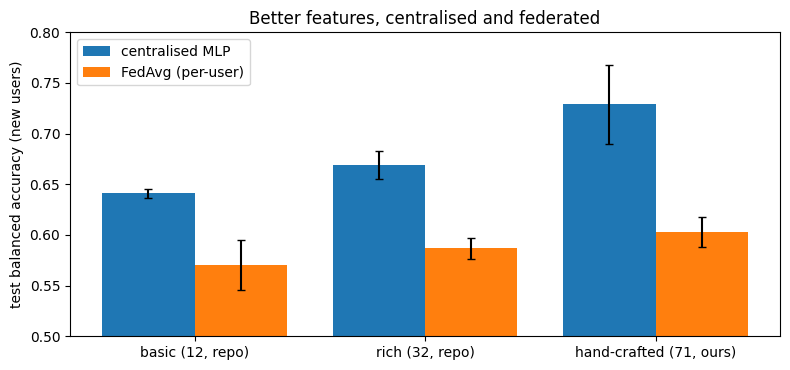

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(feature_sets))
for k, (method, label) in enumerate([("central", "centralised MLP"), ("fedavg", "FedAvg (per-user)")]):
    vals = [S[(v, method)]["test"]["balanced_accuracy"] for v in feature_sets.values()]
    ax.bar(x + (k - 0.5) * 0.4, [m["mean"] for m in vals], 0.4, yerr=[m["std"] for m in vals], capsize=3, label=label)
ax.set_xticks(x, list(feature_sets)); ax.set_ylim(0.5, 0.8); ax.set_ylabel("test balanced accuracy (new users)")
ax.set_title("Better features, centralised and federated"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "features_comparison.png", dpi=150); plt.show()

## 5. What we learn

> All numbers: mean of seeds 1–3, from the table above.

| Features | Centralised MLP, test bal. acc. | FedAvg, test bal. acc. | FedAvg, worst client |
|---|---|---|---|
| basic (12, repo) | 0.64 | 0.57 | 0.52 |
| rich (32, repo) | 0.67 | 0.59 | 0.53 |
| **hand-crafted (71, ours)** | **0.73** | **0.60** | **0.80** |

* **Better features help more than anything else we tried** (more data, the repo's extra columns). The centralised MLP gains about 9 points of balanced accuracy on new users (0.64 → 0.73), about as good as a Random Forest on the same features (0.72).
* **FedAvg improves too:** test accuracy now matches centralised (0.83 vs. 0.83), and balanced accuracy goes up a little (0.57 → 0.60).
* **The biggest change is fairness:** the weakest client goes from ≈ 0.52 to ≈ 0.80. Features that describe rhythm and frequency are more similar between people than raw levels are, so the clients' data looks less different to the model (less non-IID in feature space).
* **The gap between centralised and FedAvg on rare classes remains** (balanced accuracy 0.73 vs. 0.60). Better features reduce the non-IID problem but do not remove it, which is what Stage 2 targets.

**Cost:** ~30 lines of feature code, and the scaling step needs each client to share the sum and sum of squares of its features (not the data itself). In Stage 2 these sums could also be protected (e.g. with noise), like the model weights.